# 1. Трансформеры

Сравниваем mBERT с TF-IDF на 1799 парах. Для сравнения энкодеров исключаем группы, которые есть в train. Остается 1699 пар. Основная метрика log loss.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from experiments.metrics import quality, paired_loss

files = Path("experiments/reports/hw2")
reports = Path("experiments/reports/hw2/encoder_pairjudge_tuning")
names = ["A", "B", "tie"]

## mBERT и TF-IDF

In [2]:
def read_predictions(path):
    frame = pd.read_csv(path, dtype={"id": str}, index_col="id")
    assert frame.index.is_unique
    return frame

pred = read_predictions(files / "predictions.csv.gz")
text = pred.loc[pred.bert_A.notna()]

def class_probs(frame, model):
    return frame[[f"{model}_{label}" for label in names]]

rows = {}
for model in ["tfidf", "short_tfidf", "bert"]:
    rows[model] = quality(text.target, class_probs(text, model))
pd.DataFrame(rows).T.round(5)

,log_loss,accuracy,macro_f1
tfidf,1.06579,0.44080,0.43794
short_tfidf,1.07480,0.43802,0.43524
bert,1.08543,0.38799,0.35112


### Что меняет обрезка текста

In [4]:
controls = pd.read_csv(files / "tfidf_controls.csv.gz", dtype={"id": str})
full_text = controls[names]
clipped = class_probs(controls, "short")
delta = paired_loss(controls.target.to_numpy(), clipped, full_text, controls.group)
pd.Series(delta).round(5)

delta        0.00901
low          0.00445
high         0.01376
level        0.95000
rows      1799.00000
groups    1483.00000
dtype: float64

Обрезка до лимита BERT подняла log loss TF-IDF с 1,06579 до 1,07480.

## Длина обучения и выбор энкодера

In [6]:
parts = []
for model in ["mbert", "roberta", "modern", "pair"]:
    curve = pd.read_csv(reports / f"{model}_curve.csv")
    curve.insert(0, "model", model)
    parts.append(curve)

curves = pd.concat(parts, ignore_index=True)
curves.loc[curves.model != "pair"].round(5)

,model,epoch,n_train,n_dev,train_loss,dev_loss
0,mbert,1,5261,1534,1.05474,1.10915
1,mbert,2,5261,1534,0.98942,1.09340
2,mbert,3,5261,1534,0.88933,1.10444
3,mbert,4,5261,1534,0.73708,1.17265
4,roberta,1,5261,1534,1.06413,1.07781
5,roberta,2,5261,1534,1.11209,1.17675
6,roberta,3,5261,1534,1.01451,1.06846
7,roberta,4,5261,1534,1.00192,1.07298
8,modern,1,5261,1534,1.01861,1.07885
9,modern,2,5261,1534,0.96693,1.10837


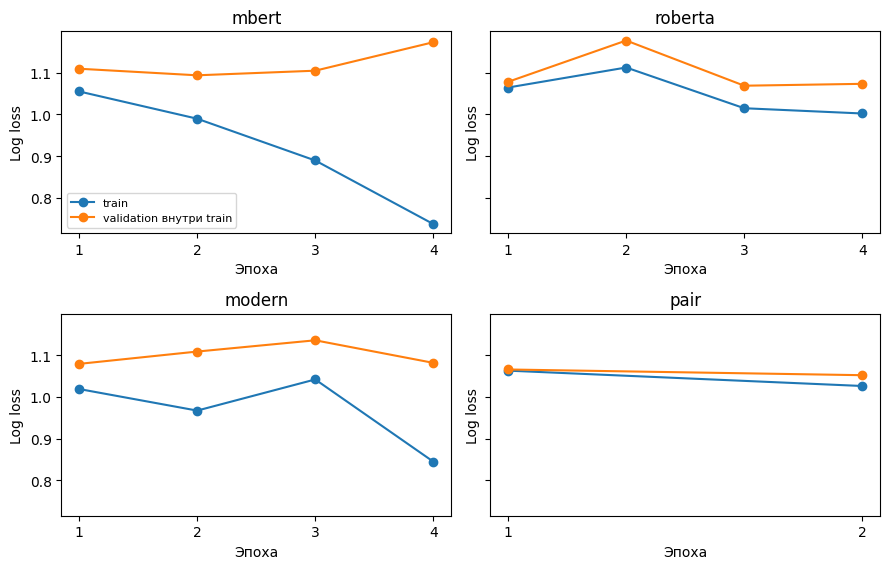

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5.8), sharey=True)
for (model, curve), ax in zip(curves.groupby("model", sort=False), axes.flat):
    ax.plot(curve.epoch, curve.train_loss, "o-", label="train")
    ax.plot(curve.epoch, curve.dev_loss, "o-", label="validation внутри train")
    ax.set(title=model, xlabel="Эпоха", xticks=curve.epoch, ylabel="Log loss")
axes.flat[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(reports / "curves.png", dpi=130)
plt.show()

In [8]:
strict = text.loc[~text.connected_to_train]
panel = pred.loc[pred.pair_A.notna()]
assert len(strict) == 1699 and len(panel) == panel.component.nunique() == 512

encoders = ["mbert_first", "mbert_longer", "mbert_best", "roberta_best", "modern_best"]
adapters = ["pair_frozen", "pair_best"]
predictions = {"tfidf": class_probs(pred, "tfidf")}
for model in encoders + adapters:
    predictions[model] = read_predictions(reports / f"{model}.csv")[names]

In [9]:
def score_models(sample, models):
    rows = []
    for model in models:
        p = predictions[model].loc[sample.index]
        rows.append({"model": model, "rows": len(sample), **quality(sample.target, p)})
    return pd.DataFrame(rows)

# У PairJudge менше пар, считаем его отдельно.
encoder_scores = score_models(strict, ["tfidf"] + encoders)
adapter_scores = score_models(panel, ["tfidf"] + adapters)
scores = pd.concat([encoder_scores, adapter_scores], ignore_index=True)
scores.to_csv(reports / "scores.csv", index=False)
encoder_scores.round(5)

,model,rows,log_loss,accuracy,macro_f1
0,tfidf,1699,1.06645,0.43555,0.43314
1,mbert_first,1699,1.06919,0.41318,0.37923
2,mbert_longer,1699,1.08458,0.36904,0.29018
3,mbert_best,1699,1.08458,0.36904,0.29018
4,roberta_best,1699,1.06700,0.38964,0.32906
5,modern_best,1699,1.06816,0.42613,0.42035


In [10]:
def compare(sample, model, reference):
    left = predictions[model].loc[sample.index]
    right = predictions[reference].loc[sample.index]
    return paired_loss(sample.target.to_numpy(), left, right, sample.component, level=0.9875)

tests = [
    ("1.1", strict, "mbert_longer", "mbert_first"),
    ("1.2a", strict, "roberta_best", "mbert_best"),
    ("1.2b", strict, "modern_best", "mbert_best"),
    ("2.1", panel, "pair_best", "pair_frozen"),
]
rows = []
for hypothesis, sample, model, reference in tests:
    delta = compare(sample, model, reference)
    rows.append(dict(hypothesis=hypothesis, model=model, reference=reference, **delta))
changes = pd.DataFrame(rows)
changes.to_csv(reports / "differences.csv", index=False)
changes.loc[changes.hypothesis != "2.1"].round(5)

,hypothesis,model,reference,delta,low,high,level,rows,groups
0,1.1,mbert_longer,mbert_first,0.01539,0.00353,0.02760,0.9875,1699,1474
1,1.2a,roberta_best,mbert_best,-0.01758,-0.03258,-0.00317,0.9875,1699,1474
2,1.2b,modern_best,mbert_best,-0.01643,-0.03242,-0.00073,0.9875,1699,1474


In [11]:
rows = []
for model, sample in [("mbert_best", strict), ("roberta_best", strict),
                      ("modern_best", strict), ("pair_best", panel)]:
    rows.append({"model": model, **compare(sample, model, "tfidf")})
vs_tfidf = pd.DataFrame(rows)
vs_tfidf.to_csv(reports / "vs_tfidf.csv", index=False)
vs_tfidf.loc[vs_tfidf.rows == 1699].round(5)

,model,delta,low,high,level,rows,groups
0,mbert_best,0.01813,-0.01090,0.04629,0.9875,1699,1474
1,roberta_best,0.00055,-0.02762,0.02980,0.9875,1699,1474
2,modern_best,0.00170,-0.02730,0.03011,0.9875,1699,1474


mBERT после одной эпохи получил 1,0854 против 1,0658 у TF-IDF на 1799 парах. На 1699 парах RoBERTa дала 1,0670 и ModernBERT 1,0682. У TF-IDF на тех же строках 1,0665. Дополнительные эпохи mBERT снизили train loss, но на внешней выборке первая эпоха оказалась лучше второй.

### MLflow

Один запуск для трех энкодеров и адаптера PairJudge.

In [12]:
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("preferences-hw2")
with mlflow.start_run(run_name="Эпохи, энкодеры и LoRA") as run_extra:
    mlflow.log_params({"seed": 42, "effective_batch": 64, "encoder_lr": 2e-5, "lora_lr": 1e-4,
                       "lora_rank": 8, "lora_alpha": 16, "weight_decay": .01})
    for name, curve in curves.groupby("model"):
        for r in curve.itertuples():
            mlflow.log_metrics({name + ".train": r.train_loss, name + ".dev": r.dev_loss}, step=r.epoch)
    for r in scores.itertuples():
        mlflow.log_metric(f"{r.model}.{r.rows}.loss", r.log_loss)
    for file in reports.iterdir():
        if file.suffix in {".csv", ".png", ".md", ".json"} and file.name != "tracking.json":
            mlflow.log_artifact(str(file))
    print("MLflow", run_extra.info.run_id)

MLflow 8c8c309863344e4fb74486c768ee7802


## Повтор эксперимента

### Подготовка данных

Для подготовки нужен train.csv. Если папка artifacts/hw2-input уже готова, переходите к обучению на GPU.

In [ ]:
%run ./baseline.ipynb

In [39]:
import re

bundle = Path("artifacts/hw2-input")
bundle.mkdir(parents=True, exist_ok=True)
pilot = pd.read_csv("experiments/reports/hw2/bert_judges/pilot_pairs.csv", dtype={"id": str})
pilot_ids = set(pilot.id)

In [40]:
technical = re.compile(
    r"\b(?:code|coding|programming|script|shell|terminal|command|sudo|python|javascript|sql|linux|"
    r"powershell|bash|curl|wget|chmod|cyber\w*|hack\w*|exploit\w*|malware|ransomware|virus|"
    r"vulnerab\w*|payload|inje[cс]t\w*|cve|metasploit|phishing|backdoor|bypass|overflow|"
    r"decoder|encoder|encrypt\w*|attack\w*|password|firewall|rootkit|reverse shell)\b", re.I)
plain = re.compile(r"""[\w\s.,!?'’‘"“”–—-]+""")
def ordinary_text(text):
    return (plain.fullmatch(text) is not None and "_" not in text
            and not technical.search(text) and not re.search(r"\w\.\w|--| {4}", text))

eligible = texts.map(ordinary_text).all(axis=1)
eligible &= ~data.id.isin(pd.read_csv("experiments/reports/hw2/bert_judges/excluded_ids.csv", dtype=str).id)
fit_rows = train_idx[eligible.iloc[train_idx].to_numpy()]
eval_rows = valid_idx[eligible.iloc[valid_idx].to_numpy()]

In [41]:
def export_rows(indices, filename):
    rows = turns.iloc[indices].copy()
    rows.insert(0, "id", data.id.iloc[indices])
    rows["target"] = y[indices]
    rows["group"] = groups.iloc[indices]
    rows["judge_test"] = rows.id.isin(pilot_ids)
    rows.to_json(bundle / filename, orient="records", lines=True, force_ascii=False)

export_rows(fit_rows, "train.jsonl")
export_rows(eval_rows, "valid.jsonl")
print("Текстовые пары", len(fit_rows), "train,", len(eval_rows), "validation")
print("Совпало с пилотом", data.id.iloc[eval_rows].isin(pilot_ids).sum())

Текстовые пары 6795 train, 1799 validation
Совпало с пилотом 20


In [42]:
from sklearn.base import clone

vocab = clone(vectorizer)
fit_text = texts.iloc[fit_rows]
vocab.fit(pd.concat([fit_text[c] for c in text_columns]))
def word_features(frame):
    return sparse.hstack([vocab.transform(frame[c]) for c in text_columns], format="csr")

with threadpool_limits(limits=4):
    word_model = clone(model).fit(word_features(fit_text), y[fit_rows])
    word_proba = word_model.predict_proba(word_features(texts.iloc[eval_rows]))
reference = pd.DataFrame(word_proba, columns=["A", "B", "tie"], index=data.id.iloc[eval_rows])
reference.to_csv(bundle / "matched_tfidf.csv")
print(metrics(y[eval_rows], word_proba))

{'log_loss': 1.0657896971178216, 'accuracy': 0.44080044469149526, 'macro_f1': 0.43794072225696024}


In [43]:
full = pd.DataFrame(probabilities, columns=["A", "B", "tie"], index=data.id.iloc[valid_idx])
full["target"] = y_valid
full["group"] = groups.iloc[valid_idx].to_numpy()
full.to_csv(bundle / "baseline_full.csv")
train_prior = np.bincount(y[fit_rows], minlength=3) / len(fit_rows)
(bundle / "train_prior.json").write_text(json.dumps(train_prior.tolist()))

59

Одинаковый первый запрос или та же пара ответов в любом порядке связывают строки в одну группу.

In [44]:
from scipy.sparse.csgraph import connected_components
import requests

pair_repo = "DaoyuanLi/pairjudge-qwen2.5-0.5b-v0.3"
pair_rev = "aa9dfb488147c45572921a3a93d00864dc1f526d"
manifest_file = bundle.parent / "pair-splits.json"
if not manifest_file.exists():
    url = f"https://huggingface.co/{pair_repo}/resolve/{pair_rev}/split-manifest.json"
    resp = requests.get(url, timeout=90)
    resp.raise_for_status()
    manifest_file.write_bytes(resp.content)
manifest = json.loads(manifest_file.read_text())
known_ids = {r["id"] for r in manifest["rows"]}
assert len(known_ids) == 9769 and known_ids.issubset(set(data.id))
author_test = {r["id"] for r in manifest["rows"] if r["split"] == "test"}
assert pilot_ids == set(data.id.iloc[valid_idx]) & author_test
replayed = pd.read_csv(bundle / "baseline_full.csv", dtype={"id": str}).set_index("id").loc[pilot.id]
assert np.array_equal(replayed.target, pilot.target)
assert np.allclose(replayed[["A", "B", "tie"]], pilot[["p_A", "p_B", "p_tie"]], rtol=1e-7, atol=1e-10)

def answer_key(turn_list):
    return tuple(" ".join(unicodedata.normalize("NFKC", s).split()).casefold() for s in turn_list)

pair_keys = pd.Series([tuple(sorted((answer_key(a), answer_key(b))))
                       for a, b in zip(turns.response_a, turns.response_b)])
questions = pd.factorize(groups)[0]
pairs = pd.factorize(pair_keys)[0] + questions.max() + 1
n = pairs.max() + 1
graph = sparse.coo_matrix((np.ones(len(data), dtype="int8"), (questions, pairs)), shape=(n, n))
component = connected_components(graph, directed=False)[1][questions]

In [45]:
valid_groups = component[valid_idx]
audit = pd.DataFrame({
    "id": data.id.iloc[valid_idx].to_numpy(),
    "component": valid_groups,
    "text": eligible.iloc[valid_idx].to_numpy(),
    "connected_to_train": np.isin(valid_groups, component[train_idx]),
    "published_component": np.isin(valid_groups, component[data.id.isin(known_ids)]),
})

pool = audit.loc[audit.text & ~audit.connected_to_train & ~audit.published_component, ["id", "component"]].copy()
pool["order"] = pool.id.map(lambda s: hashlib.sha256(("42|" + s).encode()).hexdigest())
panel = pool.sort_values("order").drop_duplicates("component").head(512)
assert len(panel) > 0 and not set(panel.id) & (known_ids | pilot_ids)
panel[["id", "component"]].to_csv(bundle / "judge_ids.csv", index=False)
print("Новых групп", pool.component.nunique(), "в сравнении", len(panel))

Новых групп 1229 в сравнении 512


In [46]:
audit["judge_panel"] = audit.id.isin(panel.id)
flags = ["connected_to_train", "published_component"]
assert not audit.loc[audit.judge_panel, flags].any().any()
audit.to_csv(bundle / "split_audit.csv", index=False)
print(audit.loc[audit.text, flags + ["judge_panel"]].sum())

connected_to_train     100
published_component    409
judge_panel            512
dtype: int64


Контроль длины. Оставляем TF-IDF тот же текст, который помещается в BERT. Словарь и регрессию обучаем заново на train.

In [ ]:
%pip install tokenizers==0.22.2 huggingface-hub==0.36.2

In [47]:
from tokenizers import Tokenizer

wordpiece = Tokenizer.from_pretrained("google-bert/bert-base-multilingual-cased",
                                    revision="3f076fdb1ab68d5b2880cb87a0886f315b8146f8")
def visible_text(indices):
    kept = pd.DataFrame(index=indices)
    for column, limit in zip(text_columns, [96, 206, 206]):
        wordpiece.enable_truncation(max_length=limit)
        strings = texts[column].iloc[indices].tolist()
        enc = wordpiece.encode_batch(strings, add_special_tokens=False)
        kept[column] = [s[:e.offsets[-1][1]] if e.offsets else "" for s, e in zip(strings, enc)]
    return kept

In [48]:
short_train, short_valid = visible_text(fit_rows), visible_text(eval_rows)
short_vocab = clone(vectorizer)
short_vocab.fit(pd.concat([short_train[c] for c in text_columns]))
def short_features(frame):
    return sparse.hstack([short_vocab.transform(frame[c]) for c in text_columns], format="csr")

with threadpool_limits(limits=4):
    short_lr = clone(model).fit(short_features(short_train), y[fit_rows])
    short_pred = short_lr.predict_proba(short_features(short_valid))
pd.DataFrame(short_pred, columns=["A","B","tie"], index=data.id.iloc[eval_rows]).to_csv(bundle / "short_tfidf.csv")
print(metrics(y[eval_rows], short_pred))

{'log_loss': 1.0747957928651677, 'accuracy': 0.43802112284602557, 'macro_f1': 0.4352367766059258}


### Обучение на GPU

Сравниваем батчи 32 и 64 на одних примерах. Затем обучаем BERT одну эпоху от исходного чекпоинта.

In [ ]:
%pip install torch==2.8.0 transformers==4.57.6 huggingface-hub==0.36.2 pairjudge==0.3.0 onnxruntime==1.23.2 sentencepiece==0.2.1 pandas==2.3.3

In [1]:
import gc
import json
import time
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, set_seed

seed = 42
bundle = Path("artifacts/hw2-input")
run = Path("artifacts") / datetime.now().strftime("hw2-%Y%m%d-%H%M%S-%f")
run.mkdir(parents=True)
models = {
    "bert": ("google-bert/bert-base-multilingual-cased", "3f076fdb1ab68d5b2880cb87a0886f315b8146f8"),
    "pair": ("DaoyuanLi/pairjudge-qwen2.5-0.5b-v0.3", "aa9dfb488147c45572921a3a93d00864dc1f526d"),
    "arena": ("dheepakkaran/arenajudge-qwen2.5-1.5b-lora-onnx-w4", "afc6132b9d6b3d050d1fab2b6f0372a9996cfa78"),
    "panda": ("WeOpenML/PandaLM-7B-v1", "f7e28bda625e6e72b4638165ef9964a35a12a4fc"),
}
config = dict(seed=seed, epochs=1, lr=2e-5, weight_decay=0.01, limits=[96, 206, 206],
              dtype="bfloat16", gpu=torch.cuda.get_device_name(), models=models, torch=torch.__version__)
assert torch.cuda.is_bf16_supported()
print(config["gpu"], run)

NVIDIA H100 80GB HBM3 artifacts/hw2-20261122-212001-625889


In [2]:
train = pd.read_json(bundle / "train.jsonl", lines=True, dtype={"id": str}).set_index("id")
valid = pd.read_json(bundle / "valid.jsonl", lines=True, dtype={"id": str}).set_index("id")
fields = ["prompt", "response_a", "response_b"]
assert train.index.is_unique and valid.index.is_unique and not set(train.group) & set(valid.group)
tok = AutoTokenizer.from_pretrained(models["bert"][0], revision=models["bert"][1])
pad = DataCollatorWithPadding(tok, pad_to_multiple_of=8)
print(len(train), len(valid))

6795 1799


In [3]:
def bert_inputs(frame):
    parts = []
    for field, limit in zip(fields, config["limits"]):
        strings = frame[field].map("\n".join).tolist()
        parts.append(tok(strings, add_special_tokens=False, truncation=True, max_length=limit)["input_ids"])
    records = []
    for q, a, b, y in zip(*parts, frame.target):
        ids = [tok.cls_token_id] + q + [tok.sep_token_id] + a + [tok.sep_token_id] + b + [tok.sep_token_id]
        records.append({"input_ids": ids, "labels": int(y)})
    return records

encoded_train = bert_inputs(train)
encoded_valid = bert_inputs(valid)

In [4]:
def batches(rows, size, shuffle=False):
    return DataLoader(rows, batch_size=size, shuffle=shuffle, collate_fn=pad, pin_memory=True,
                      generator=torch.Generator().manual_seed(seed))

def new_bert():
    set_seed(seed)
    net = AutoModelForSequenceClassification.from_pretrained(
        models["bert"][0], revision=models["bert"][1], num_labels=3, use_safetensors=True).cuda()
    optimizer = torch.optim.AdamW(net.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    return net, optimizer

def update_bert(net, optimizer, batch):
    optimizer.zero_grad(set_to_none=True)
    with torch.autocast("cuda", dtype=torch.bfloat16):
        loss = net(**batch.to("cuda")).loss
    loss.backward()
    optimizer.step()
    return loss.detach()

In [5]:
def measure_batch(size, sample):
    net, opt = new_bert()
    net.train()
    for batch in batches(sample[:128], size):
        update_bert(net, opt, batch)
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    seconds = []
    for _ in range(3):
        start = time.perf_counter()
        for batch in batches(sample, size):
            update_bert(net, opt, batch)
        torch.cuda.synchronize()
        seconds.append(time.perf_counter() - start)
    return len(sample) / np.median(seconds), torch.cuda.max_memory_allocated() / 2**30

rng = np.random.default_rng(seed)
sample = [encoded_train[i] for i in rng.permutation(len(train))[:1024]]
bench = []
for size in (32, 64):
    try:
        speed, memory = measure_batch(size, sample)
        bench.append((size, speed, memory, "ok"))
    except torch.OutOfMemoryError:
        bench.append((size, np.nan, np.nan, "out of memory"))
    gc.collect()
    torch.cuda.empty_cache()
bench = pd.DataFrame(bench, columns=["batch", "pairs_per_second", "peak_GiB", "status"])
bench.to_csv(run / "batches.csv", index=False)
print(bench.to_string(index=False))

 batch  pairs_per_second  peak_GiB status
    32        579.694223  8.653915     ok
    64        632.471924 15.050888     ok


In [6]:
batch_size = int(bench.loc[bench.pairs_per_second.idxmax(), "batch"])
config["batch_size"] = batch_size
(run / "config.json").write_text(json.dumps(config, indent=2))
net, opt = new_bert()
net.train()
start = time.perf_counter()
trace = []
rolling = []
for step, batch in enumerate(batches(encoded_train, batch_size, shuffle=True), start=1):
    rolling.append(update_bert(net, opt, batch))
    if step % 50 == 0 or step == (len(train) + batch_size - 1) // batch_size:
        loss = torch.stack(rolling).mean().item()
        trace.append((step, loss, time.perf_counter() - start))
        print(step, round(loss, 4), round(trace[-1][2], 1), flush=True)
        rolling.clear()
pd.DataFrame(trace, columns=["step", "train_loss", "seconds"]).to_csv(run / "learning.csv", index=False)

50 1.1003 5.1
100 1.0906 10.1
107 1.0515 10.8


In [7]:
labels3 = ["A", "B", "tie"]
def save_predictions(name, ids, values):
    values = np.asarray(values, dtype=np.float64)
    assert len(ids) and values.shape == (len(ids), 3) and pd.Index(ids).is_unique
    assert np.isfinite(values).all() and (values >= 0).all() and np.allclose(values.sum(1), 1, atol=1e-5)
    frame = pd.DataFrame(values / values.sum(axis=1, keepdims=True), index=ids, columns=labels3)
    frame.index.name = "id"
    frame.to_csv(run / (name + ".csv"))

net.eval()
pred = []
with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
    for batch in batches(encoded_valid, batch_size):
        batch.pop("labels")
        pred.extend(net(**batch.to("cuda")).logits.float().softmax(-1).cpu().numpy())
save_predictions("bert", valid.index, pred)
net.save_pretrained(run / "bert-checkpoint")
del net, opt
gc.collect()
torch.cuda.empty_cache()
print("Прогнозов BERT", len(pred))

Прогнозов BERT 1799


In [ ]:
(bundle / "bert_run.txt").write_text(str(run))

### Выбор эпох для mBERT, RoBERTa и ModernBERT

У каждой модели проверяем от одной до четырех эпох на внутренней валидации. Затем обучаем заново на всем train.

In [ ]:
%pip install peft==0.18.0 accelerate==1.12.0 networkx==3.4.2

In [ ]:
from experiments.epochs import run_models

run_models(["mbert", "roberta", "modern"])